In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # Hide UserWarnings

In [2]:
X, y_true = make_blobs(n_samples=500, centers=3, n_features=2, cluster_std = 0.60, random_state=0)

In [3]:
df = pd.DataFrame(X, columns = ['Feature_1', 'Feature_2'])

In [4]:
df

,Feature_1,Feature_2
0,1.052417,4.544981
1,-1.770469,3.352503
2,-1.831415,2.286754
3,1.360349,3.333614
4,-0.185498,4.417054
...,...,...
495,2.418340,1.434997
496,2.547461,1.713633
497,2.518111,1.515327
498,0.333819,4.936458


In [5]:
# do standard scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [6]:
# check the curve in elbow method 

inertia = []
K_range = range(1,11)

In [7]:
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

In [8]:
inertia

[1000.0000000000003,
 404.181484080335,
 138.48971856185543,
 120.03296145328518,
 111.38422447852838,
 95.4362513145374,
 83.62787134261356,
 70.26414440662822,
 58.9061797664464,
 56.11013453595797]

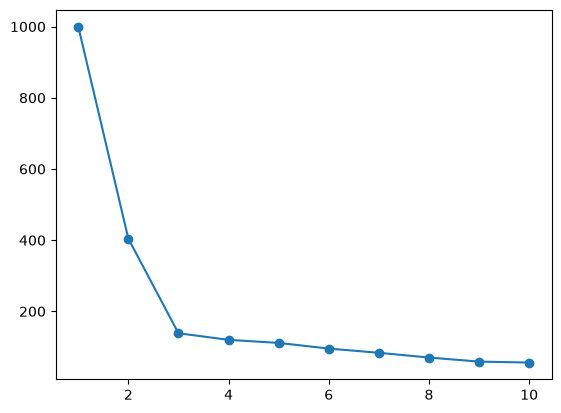

In [9]:
plt.plot(K_range, inertia, marker ='o')

In [10]:
kmeans = KMeans(n_clusters=2, random_state=42)
cluster_labels = kmeans.fit_predict(X_scaled)

In [11]:
df['cluster'] = cluster_labels

In [12]:
df

,Feature_1,Feature_2,cluster
0,1.052417,4.544981,1
1,-1.770469,3.352503,1
2,-1.831415,2.286754,1
3,1.360349,3.333614,1
4,-0.185498,4.417054,1
...,...,...,...
495,2.418340,1.434997,0
496,2.547461,1.713633,0
497,2.518111,1.515327,0
498,0.333819,4.936458,1


<Axes: xlabel='Feature_1', ylabel='Feature_2'>

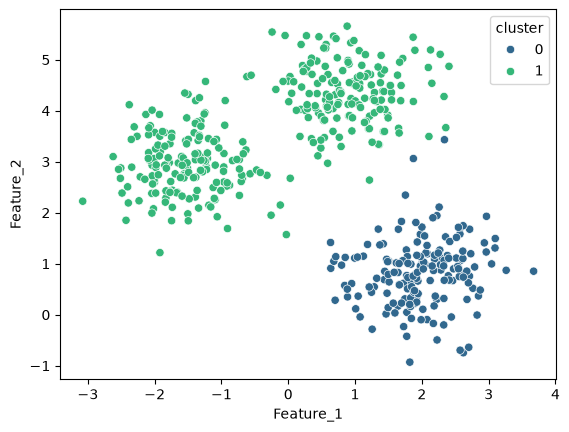

In [13]:
#scatterplot
sns.scatterplot(x=df['Feature_1'], y=df['Feature_2'], hue=df['cluster'], palette='viridis')

In [14]:
# make moons 
from sklearn.datasets import make_moons


In [15]:
X, y_true = make_moons(n_samples=500, noise=0.05, random_state=42)
df =pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])

In [16]:
from sklearn.cluster import KMeans, DBSCAN

In [17]:
# scale the values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [18]:
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

In [19]:
df['kmeans_cluster'] = kmeans_labels

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

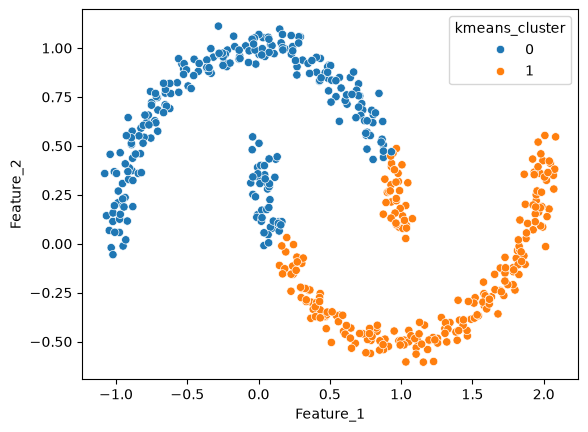

In [20]:
#scatter plot
sns.scatterplot(x=df['Feature_1'],
                y=df['Feature_2'],
                hue = df['kmeans_cluster'], 
                palette='tab10')

In [21]:
# using DB Scan because kmeans makes two clusters

dbscan = DBSCAN(eps=0.3, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

In [22]:
# Now get the labels 
df['dbscan_cluster'] =dbscan_labels

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

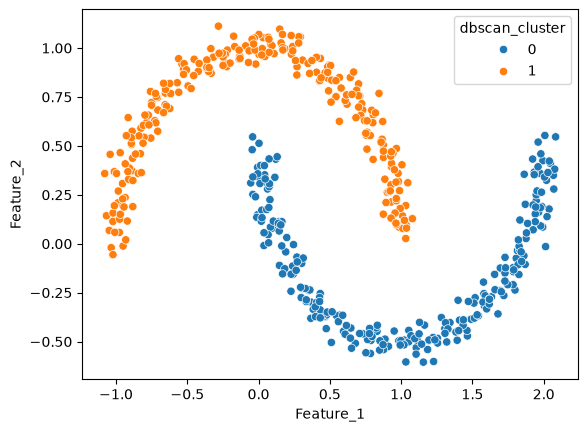

In [23]:
# make scatter plot
sns.scatterplot(x=df['Feature_1'], 
                y=df['Feature_2'], 
                hue=df['dbscan_cluster'],
                palette='tab10')